# COMP5318 Assignment 2 — Traditional model optimisation
Random Forest only. Original group template remains available; merge these cells into its corresponding sections.

## Setup and dependencies
Use requirements.txt. Run from the assignment2 directory. Full training logic is embedded below; cached experiments are reused. All experiment records remain on disk.

In [1]:
from IPython.display import display, Image
"""Auditable staged Random Forest optimisation; test data are used only after selection."""
from pathlib import Path
from datetime import datetime, timezone
from time import perf_counter
import hashlib
import json
import os
import platform
import shutil
import traceback
import numpy as np
import pandas as pd
import sklearn
import joblib
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split, ParameterGrid
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

ROOT = Path.cwd()
DATA = ROOT/'Assignment2Data'
RUN = ROOT/'optimization_20261018'
SEED = 42
JOBS = 4

def utc(): return datetime.now(timezone.utc).isoformat()
def dump(path, obj):
    path.write_text(json.dumps(obj, indent=2, ensure_ascii=False, default=lambda x: x.item() if isinstance(x, np.generic) else str(x)), encoding='utf-8')
def digest(path):
    h=hashlib.sha256()
    with open(path,'rb') as f:
        for block in iter(lambda:f.read(1024*1024), b''): h.update(block)
    return h.hexdigest()
def event(kind, **details):
    item={'timestamp_utc':utc(), 'event':kind, **details}
    with (RUN/'events.jsonl').open('a',encoding='utf-8') as f: f.write(json.dumps(item,ensure_ascii=False)+'\n')
    print(json.dumps(item,ensure_ascii=False),flush=True)

def features(images, name):
    x=images.astype(np.float32)/255.
    if name=='raw_rgb': return x.reshape(len(x),-1)
    if name=='pooled_rgb': return x.reshape(-1,14,2,14,2,3).mean(axis=(2,4)).reshape(len(x),-1)
    if name=='colour_texture':
        # Fixed, non-learned descriptors: 7x7 spatial blocks of size 4x4.
        blocks=x.reshape(-1,7,4,7,4,3)
        mean=blocks.mean(axis=(2,4)).reshape(len(x),-1)
        std=blocks.std(axis=(2,4)).reshape(len(x),-1)
        # Per-channel 16-bin histograms, normalised to sum to one.
        bins=np.minimum((x*16).astype(np.int16),15).reshape(len(x),-1,3)
        hist=np.stack([(bins[:,:,c]==b).mean(axis=1) for c in range(3) for b in range(16)],axis=1)
        quant=np.quantile(x.reshape(len(x),-1,3),[.1,.25,.5,.75,.9],axis=1).transpose(1,0,2).reshape(len(x),-1)
        return np.concatenate([mean,std,hist,quant],axis=1).astype(np.float32)
    raise ValueError(name)

def initialise():
    RUN.mkdir(exist_ok=True)
    if not (RUN/'manifest.json').exists():
        archive=RUN/'prior_experiment'; archive.mkdir()
        shutil.copytree(ROOT/'results',archive/'results')
        shutil.copy2(ROOT/'traditional_random_forest.ipynb',archive)
        shutil.copy2(ROOT/'requirements.txt',RUN/'requirements.txt')
        dump(RUN/'manifest.json',{'created_utc':utc(),'python':platform.python_version(),
             'sklearn':sklearn.__version__,'numpy':np.__version__,'platform':platform.platform(),
             'seed':SEED,'n_jobs':JOBS,'selection_metric':'validation macro-F1',
             'data_sha256':{p.name:digest(p) for p in DATA.glob('*.npy')},
             'prior_test_exposure':'Original 8-trial experiment has already evaluated this test set. Further choices use validation only; this is not a never-seen test set.',
             'scope':'Best among the evaluated configurations, not a global optimum.'})
        dump(RUN/'plan.json',{
          'stage1':'3 feature representations x leaf sizes [1,4], 100 trees, sqrt features, unlimited depth',
          'stage2':'Best representation; 100 trees; max_features [sqrt,0.1,0.3] x max_depth [16,None] x leaf [1,4]',
          'stage3':'Best two structural configurations; compare 200 and 400 trees',
          'stage4':'Best two stage3 candidates; repeat at seeds 17 and 73, rank mean validation macro-F1 over seeds 42,17,73',
          'final':'Freeze configuration; refit all training data with seed 42; evaluate provided test set once for this run',
          'tie_break':'macro-F1 then accuracy; stable earlier trial order',
          'limitation':'One fixed validation split is reused; seed repeats measure model randomness, not split uncertainty.'})
        event('initialised')
    images=np.load(DATA/'X_train.npy',allow_pickle=False)
    y=np.load(DATA/'y_train.npy',allow_pickle=False).ravel()
    splitfile=RUN/'split_indices.npz'
    if not splitfile.exists():
        fit,val=train_test_split(np.arange(len(y)),test_size=.2,stratify=y,random_state=SEED)
        np.savez(splitfile,fit_idx=fit,val_idx=val)
    with np.load(splitfile) as z: fit,val=z['fit_idx'],z['val_idx']
    np.save(RUN/'training_labels.npy',y)
    return images,y,fit,val

def records():
    return [json.loads(p.read_text(encoding='utf-8')) for p in sorted((RUN/'trials').glob('*/result.json'))]

def trial(stage, representation, params, seed, images, y, fit, val, cache):
    config={'representation':representation,'params':params,'seed':seed}
    key=hashlib.sha256(json.dumps(config,sort_keys=True).encode()).hexdigest()[:12]
    folder=RUN/'trials'/key; folder.mkdir(parents=True,exist_ok=True)
    if (folder/'result.json').exists():
        event('reuse_trial',stage=stage,trial_id=key)
        return json.loads((folder/'result.json').read_text(encoding='utf-8'))
    model=RandomForestClassifier(**params,random_state=seed,n_jobs=JOBS)
    dump(folder/'config.json',{'stage':stage,**config,'full_estimator_params':model.get_params(),'started_utc':utc()})
    event('trial_started',stage=stage,trial_id=key,**config)
    try:
        if representation not in cache:
            start=perf_counter(); cache[representation]=features(images,representation)
            event('features_ready',representation=representation,seconds=perf_counter()-start,dimensions=cache[representation].shape[1])
        X=cache[representation]; start=perf_counter()
        model.fit(X[fit],y[fit]); fit_seconds=perf_counter()-start
        start=perf_counter(); proba=model.predict_proba(X[val]); predict_seconds=perf_counter()-start
        pred=model.classes_[proba.argmax(axis=1)]; trainpred=model.predict(X[fit])
        result={'trial_id':key,'stage':stage,**config,'finished_utc':utc(),
            'feature_count':X.shape[1],'fit_samples':len(fit),'val_samples':len(val),
            'train_accuracy':accuracy_score(y[fit],trainpred),'train_macro_f1':f1_score(y[fit],trainpred,average='macro'),
            'val_accuracy':accuracy_score(y[val],pred),'val_macro_f1':f1_score(y[val],pred,average='macro'),
            'fit_seconds':fit_seconds,'val_predict_seconds':predict_seconds}
        np.savez_compressed(folder/'predictions.npz',fit_indices=fit,train_true=y[fit],train_pred=trainpred,
            val_indices=val,val_true=y[val],val_pred=pred,val_probabilities=proba,classes=model.classes_)
        pd.DataFrame(classification_report(y[val],pred,output_dict=True,zero_division=0)).T.to_csv(folder/'classification_report.csv')
        np.save(folder/'confusion_matrix.npy',confusion_matrix(y[val],pred,labels=model.classes_))
        joblib.dump(model,folder/'model.joblib',compress=3)
        dump(folder/'result.json',result)
        flat=[{**{k:v for k,v in r.items() if k!='params'},**r['params']} for r in records()]
        pd.DataFrame(flat).to_csv(RUN/'all_trials.csv',index=False)
        event('trial_finished',**result)
        return result
    except Exception:
        (folder/'error.txt').write_text(traceback.format_exc(),encoding='utf-8')
        event('trial_failed',trial_id=key)
        raise

def ranked(rows): return sorted(rows,key=lambda r:(r['val_macro_f1'],r['val_accuracy']),reverse=True)

def optimise():
    if (RUN/'selection_frozen.json').exists():
        event('reuse_frozen_selection')
        return json.loads((RUN/'selection_frozen.json').read_text(encoding='utf-8'))
    images,y,fit,val=initialise(); cache={}
    def run(stage,rep,p,seed=SEED): return trial(stage,rep,p,seed,images,y,fit,val,cache)
    stage1=[]
    for rep in ['pooled_rgb','raw_rgb','colour_texture']:
        for leaf in [1,4]:
            stage1.append(run('1_features',rep,dict(n_estimators=100,max_features='sqrt',max_depth=None,min_samples_leaf=leaf)))
    rep=ranked(stage1)[0]['representation']
    event('feature_selected',representation=rep,criterion='validation macro-F1')
    stage2=[]
    for p in ParameterGrid({'max_features':['sqrt',.1,.3],'max_depth':[16,None],'min_samples_leaf':[1,4]}):
        stage2.append(run('2_structure',rep,dict(n_estimators=100,**p)))
    stage3=[]
    for r in ranked(stage2)[:2]:
        for n in [200,400]: stage3.append(run('3_tree_count',rep,{**r['params'],'n_estimators':n}))
    candidates=[]
    for r in ranked(stage3)[:2]:
        repeats=[r]+[run('4_seed_stability',rep,r['params'],seed) for seed in [17,73]]
        candidates.append({'representation':rep,'params':r['params'],'trial_ids':[v['trial_id'] for v in repeats],
            'mean_val_macro_f1':float(np.mean([v['val_macro_f1'] for v in repeats])),
            'std_val_macro_f1':float(np.std([v['val_macro_f1'] for v in repeats],ddof=1)),
            'mean_val_accuracy':float(np.mean([v['val_accuracy'] for v in repeats]))})
    best=max(candidates,key=lambda r:(r['mean_val_macro_f1'],r['mean_val_accuracy']))
    dump(RUN/'seed_comparison.json',candidates)
    dump(RUN/'selection_frozen.json',{'frozen_utc':utc(),**best,'final_seed':SEED})
    event('selection_frozen',**best)
    return best

def final_evaluation(config):
    # Independent of search variables: only the literal config and original arrays are needed.
    dest=RUN/'final';dest.mkdir(parents=True,exist_ok=True)
    if (dest/'metrics.json').exists():
        saved=json.loads((dest/'config.json').read_text(encoding='utf-8'))
        if saved['representation'] != config['representation'] or any(saved['full_estimator_params'][k]!=v for k,v in config['params'].items()):
            raise ValueError('Cached final model has different parameters. Choose a new RUN directory; do not overwrite the audit trail.')
        event('final_already_completed')
        return json.loads((dest/'metrics.json').read_text(encoding='utf-8'))
    images=np.load(DATA/'X_train.npy',allow_pickle=False); y=np.load(DATA/'y_train.npy',allow_pickle=False).ravel()
    start=perf_counter(); X=features(images,config['representation']); train_feature_s=perf_counter()-start
    model=RandomForestClassifier(**config['params'],random_state=SEED,n_jobs=JOBS)
    dump(dest/'config.json',{'representation':config['representation'],'full_estimator_params':model.get_params()})
    start=perf_counter();model.fit(X,y);fit_s=perf_counter()-start
    joblib.dump(model,dest/'model.joblib',compress=3)
    # Test arrays are first loaded here, after configuration freezing and final fitting.
    xt=np.load(DATA/'X_test.npy',allow_pickle=False);yt=np.load(DATA/'y_test.npy',allow_pickle=False).ravel()
    start=perf_counter();Xt=features(xt,config['representation']);test_feature_s=perf_counter()-start
    start=perf_counter();prob=model.predict_proba(Xt);pred=model.classes_[prob.argmax(axis=1)];predict_s=perf_counter()-start
    np.savez_compressed(dest/'test_predictions.npz',sample_indices=np.arange(len(yt)),true_labels=yt,predicted_labels=pred,probabilities=prob,classes=model.classes_)
    table=pd.DataFrame({'sample_index':np.arange(len(yt)),'true_label':yt,'predicted_label':pred})
    for i,c in enumerate(model.classes_):table[f'prob_class_{c}']=prob[:,i]
    table.to_csv(dest/'test_predictions.csv',index=False)
    pd.DataFrame(classification_report(yt,pred,output_dict=True,zero_division=0)).T.to_csv(dest/'classification_report.csv')
    cm=confusion_matrix(yt,pred,labels=model.classes_);np.save(dest/'confusion_matrix.npy',cm)
    metrics={'test_accuracy':accuracy_score(yt,pred),'test_macro_f1':f1_score(yt,pred,average='macro'),
       'train_samples':len(y),'test_samples':len(yt),'fit_seconds':fit_s,'predict_seconds':predict_s,
       'train_feature_seconds':train_feature_s,'test_feature_seconds':test_feature_s}
    dump(dest/'metrics.json',metrics);event('final_completed',**metrics)
    return metrics



## 1. Data loading and preprocessing
Training/validation split is fixed and stratified (25,600 / 6,400). The test data are not used for selection. The three feature representations are defined in features().

In [2]:
images, y, fit_idx, val_idx = initialise()
print(images.shape, len(fit_idx), len(val_idx))
print(pd.Series(y).value_counts().sort_index())

(32000, 28, 28, 3) 25600 6400
0    3490
1    3431
2    3505
3    3656
4    2950
5    4290
6    2728
7    3253
8    4697
Name: count, dtype: int64


## 2. Algorithm design
Random Forest uses bootstrapped trees and random feature subsets. Structural flexibility, tree correlation, and runtime motivate the parameter search. No feature transform is fitted on validation or test data.

In [3]:
baseline = RandomForestClassifier(n_estimators=100, max_features='sqrt', random_state=42, n_jobs=4)
print(baseline)
print((RUN/'plan.json').read_text())

RandomForestClassifier(n_jobs=4, random_state=42)
{
  "stage1": "3 feature representations x leaf sizes [1,4], 100 trees, sqrt features, unlimited depth",
  "stage2": "Best representation; 100 trees; max_features [sqrt,0.1,0.3] x max_depth [16,None] x leaf [1,4]",
  "stage3": "Best two structural configurations; compare 200 and 400 trees",
  "stage4": "Best two stage3 candidates; repeat at seeds 17 and 73, rank mean validation macro-F1 over seeds 42,17,73",
  "final": "Freeze configuration; refit all training data with seed 42; evaluate provided test set once for this run",
  "tie_break": "macro-F1 then accuracy; stable earlier trial order",
  "limitation": "One fixed validation split is reused; seed repeats measure model randomness, not split uncertainty."
}


## 3. Hyperparameter tuning
This cell can be skipped for final fitting. It runs the staged search or reuses fully recorded completed trials. The original timestamped training log is events.jsonl. Each trial stores parameters, model and per-sample validation predictions.

In [4]:
# If completed, this preserves and reloads the originally frozen selection.
selected = optimise()
print(json.dumps(selected, indent=2))

{"timestamp_utc": "2026-10-18T15:38:52.854439+00:00", "event": "reuse_frozen_selection"}


{
  "frozen_utc": "2026-10-18T06:19:19.180884+00:00",
  "representation": "colour_texture",
  "params": {
    "n_estimators": 400,
    "max_depth": null,
    "max_features": 0.3,
    "min_samples_leaf": 1
  },
  "trial_ids": [
    "668e7290f081",
    "bb07e7d2b53e",
    "a4870ec145cd"
  ],
  "mean_val_macro_f1": 0.8497640541284638,
  "std_val_macro_f1": 0.0003750550985671843,
  "mean_val_accuracy": 0.8544270833333334,
  "final_seed": 42
}


,experiment_number,trial_id,stage,representation,seed,finished_utc,feature_count,fit_samples,val_samples,train_accuracy,train_macro_f1,val_accuracy,val_macro_f1,fit_seconds,val_predict_seconds,n_estimators,max_depth,max_features,min_samples_leaf
0,1,eeef7b6ee7f3,1_features,pooled_rgb,42,2026-10-18T05:50:18.498575+00:00,588,25600,6400,1.000000,1.000000,0.646563,0.621581,11.091667,0.061356,100,NaN,sqrt,1
1,2,aa8b1e227cf0,1_features,pooled_rgb,42,2026-10-18T05:50:29.017745+00:00,588,25600,6400,0.988008,0.987776,0.645312,0.614456,9.232675,0.040596,100,NaN,sqrt,4
2,3,e256607009f2,1_features,raw_rgb,42,2026-10-18T05:50:48.605720+00:00,2352,25600,6400,1.000000,1.000000,0.630625,0.600015,18.186715,0.105735,100,NaN,sqrt,1
3,4,5178a152bfdd,1_features,raw_rgb,42,2026-10-18T05:51:05.796036+00:00,2352,25600,6400,0.992461,0.992333,0.634531,0.601071,15.678811,0.094449,100,NaN,sqrt,4
4,5,bf68c5e8977a,1_features,colour_texture,42,2026-10-18T05:51:21.181724+00:00,357,25600,6400,1.000000,1.000000,0.830000,0.824161,9.264220,0.038106,100,NaN,sqrt,1
5,6,f12d52d29041,1_features,colour_texture,42,2026-10-18T05:51:30.837220+00:00,357,25600,6400,0.983750,0.983234,0.827187,0.821494,8.701434,0.037561,100,NaN,sqrt,4
6,7,a58ce4b289aa,2_structure,colour_texture,42,2026-10-18T05:51:40.173385+00:00,357,25600,6400,0.994648,0.994431,0.824844,0.818853,8.588993,0.037833,100,16.0,sqrt,1
7,8,2ddf262d1583,2_structure,colour_texture,42,2026-10-18T05:51:48.812460+00:00,357,25600,6400,0.966367,0.965440,0.821562,0.815304,7.856977,0.037582,100,16.0,sqrt,4
8,9,c898c8e839ad,2_structure,colour_texture,42,2026-10-18T05:52:05.825602+00:00,357,25600,6400,0.990547,0.990295,0.836719,0.830761,16.333043,0.037355,100,16.0,0.1,1
9,10,f9a258555350,2_structure,colour_texture,42,2026-10-18T05:52:21.755088+00:00,357,25600,6400,0.966094,0.965211,0.835781,0.830862,15.181884,0.037365,100,16.0,0.1,4


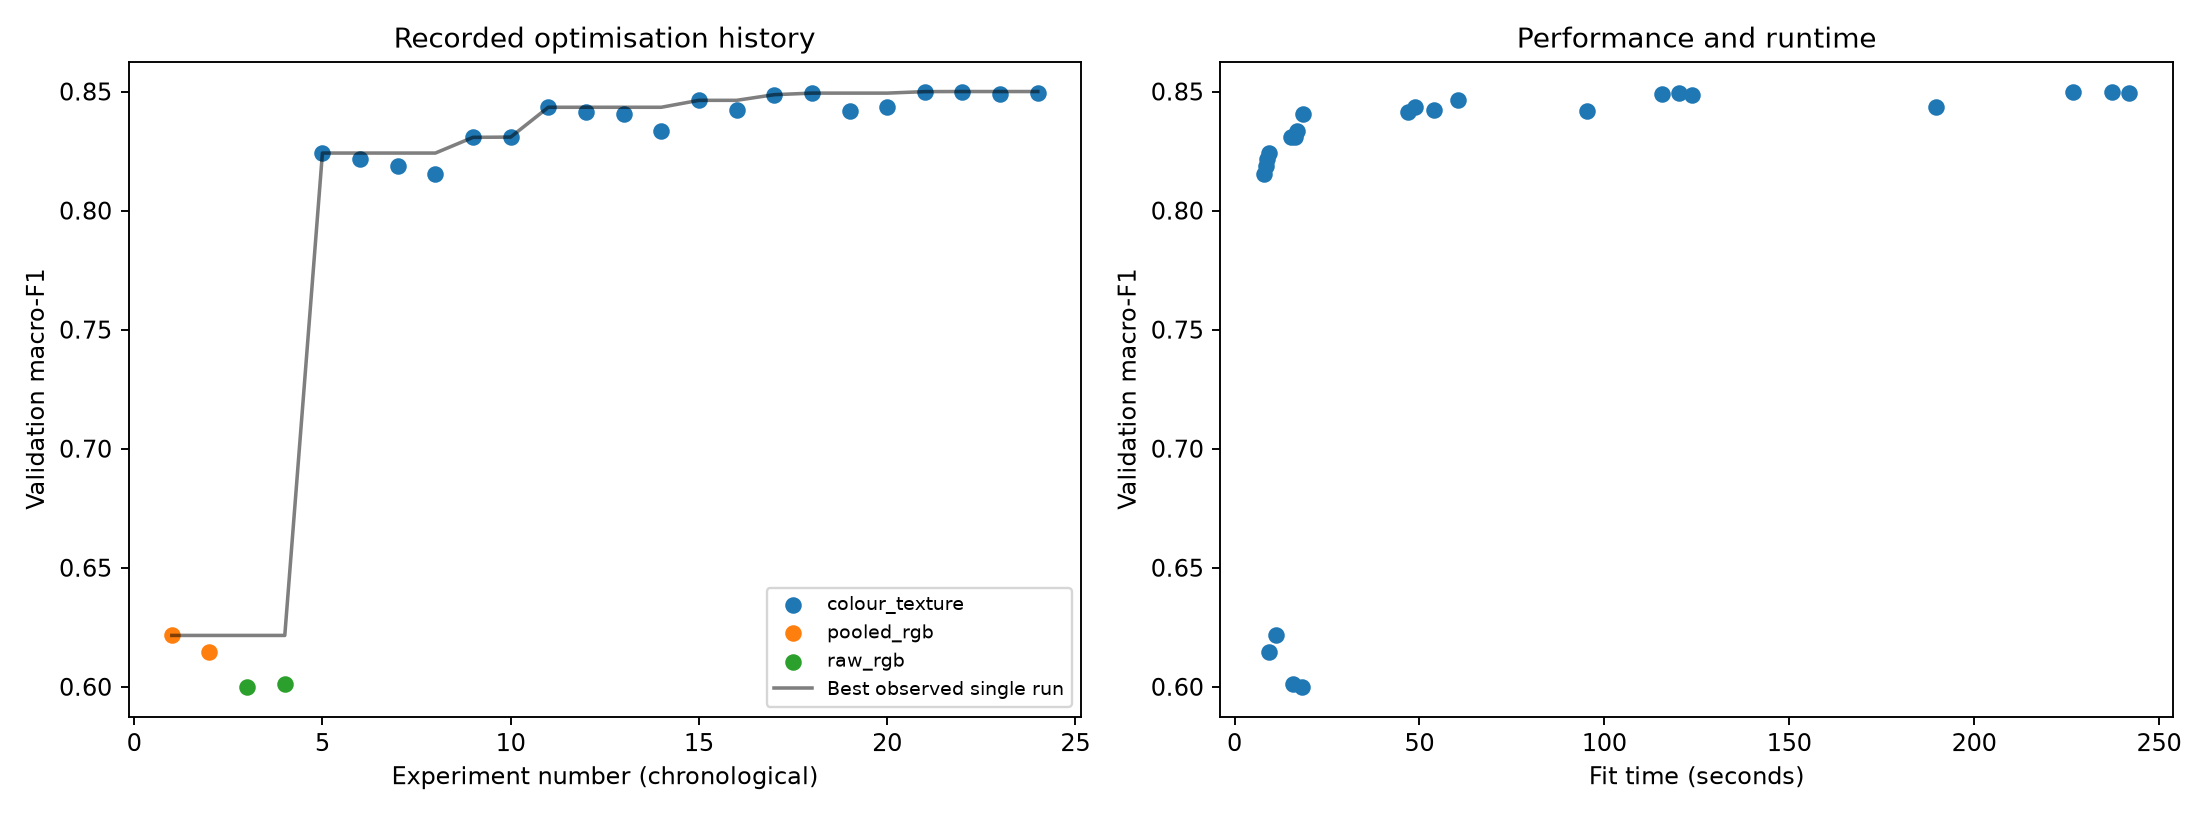

,representation,params,trial_ids,mean_val_macro_f1,std_val_macro_f1,mean_val_accuracy
0,colour_texture,"{'n_estimators': 400, 'max_depth': None, 'max_...","[668e7290f081, bb07e7d2b53e, a4870ec145cd]",0.849764,0.000375,0.854427
1,colour_texture,"{'n_estimators': 200, 'max_depth': None, 'max_...","[1e52287cbb11, 26a3f4d6407f, ed4f902ca10e]",0.848926,0.000327,0.853646


In [5]:
from IPython.display import display, Image
history = pd.read_csv(RUN/'experiment_history.csv')
display(history)
display(Image(filename=str(RUN/'optimization_history.png')))
display(pd.DataFrame(json.loads((RUN/'seed_comparison.json').read_text())))

## 4. Final model
Frozen literal configuration. This cell works without the search cell after setup. Existing final results are reused; a fresh RUN directory causes independent fitting and evaluation. Do not overwrite the audit directory or tune from test outcomes.

{"timestamp_utc": "2026-10-18T15:38:52.900673+00:00", "event": "final_already_completed"}


,test_accuracy,test_macro_f1,train_samples,test_samples,fit_seconds,predict_seconds,train_feature_seconds,test_feature_seconds
0,0.860625,0.856244,32000,8000,300.022457,0.151341,5.622832,1.185781


,precision,recall,f1-score,support
0,0.978385,0.985109,0.981735,873.000000
1,0.992974,0.988345,0.990654,858.000000
2,0.839726,0.698974,0.762912,877.000000
3,0.945856,0.936543,0.941176,914.000000
4,0.813433,0.887381,0.848799,737.000000
5,0.842009,0.860075,0.850946,1072.000000
6,0.781790,0.730205,0.755118,682.000000
7,0.732165,0.719557,0.725806,813.000000
8,0.808790,0.893526,0.849049,1174.000000
accuracy,0.860625,0.860625,0.860625,0.860625


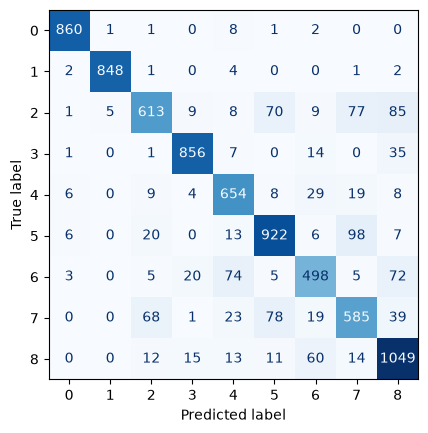

In [6]:
FINAL_CONFIG = {'representation': 'colour_texture', 'params': {'n_estimators': 400, 'max_depth': None, 'max_features': 0.3, 'min_samples_leaf': 1}}
final_metrics = final_evaluation(FINAL_CONFIG)
display(pd.DataFrame([final_metrics]))
display(pd.read_csv(RUN/'final/classification_report.csv', index_col=0))
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay
ConfusionMatrixDisplay(np.load(RUN/'final/confusion_matrix.npy')).plot(cmap='Blues', colorbar=False)
plt.show()

## 5. AI acknowledgement and limitations
OpenAI Codex assisted with code, execution, record keeping and summaries. Team members must review and understand the implementation. The same validation split was reused across stages; seed stability is not cross-validation. The original experiment had already evaluated the test set. This search establishes the best selected configuration within this experimental budget, not a global optimum.